# 06 · EDA step 5: pre-game predictors (women's)

**Question:** which pre-game features predict who wins, over which window, and which are worth
putting in the model? The women's copy of the men's step 5, with the rules in
[docs/eda_plan_women.md](../../docs/eda_plan_women.md).

## Rules (fixed before running)

1. **Data:** 579 games (2025-26, D-I that season, no ties, both teams past the warm-up).
   `TimeSeriesSplit(4)` from step 1. **Folds 1–3 are for choosing; fold 4 is untouched**
   until the confirmation cell at the end.
2. **Score each feature alone:** a one-feature logistic regression fit on the training part
   of each fold (standardized inside the fold). **gain** = baseline log loss − feature log
   loss on the fold's test games; the baseline always predicts the training home win rate.
   AUC is reported alongside.
3. **Keep a feature only if** its mean gain over folds 1–3 is above 0 **and** it beats the
   baseline in at least 2 of the 3 folds (a majority).
4. **Window choice** (tier 1 stats only, the women's tiers from step 4): the window with the
   best mean gain, unless the season-to-date window is within one standard error of it (from
   the three paired fold differences), in which case the season.
5. **Overlap:** strongest to weakest, drop a feature with |r| ≥ 0.8 to one already kept.
6. **Confirm once on fold 4** (trained on everything before it). A shortlisted feature that
   doesn't beat the baseline there is **flagged**, not dropped. Fold 4 includes the conference
   and NCAA tournaments.

Home ice, rest and back-to-backs are step 6.


In [1]:
%run ./02_choose_k.ipynb

/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_44394/2041251285.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["home_win"] = out["result"].map({"W": 1, "L": 0})  # NaN for ties
/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_44394/2041251285.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return out.reset_index().sort_values(["game_date", "game_id"]).reset_index(drop=True)
/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_44394/2041251285.py:39: PerformanceWarning: DataFrame is high

All leakage checks passed.


/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_44394/2041251285.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["home_win"] = out["result"].map({"W": 1, "L": 0})  # NaN for ties
/var/folders/72/ygtskn4x6gq5fmq9wy6cvllw0000gn/T/ipykernel_44394/2041251285.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return out.reset_index().sort_values(["game_date", "game_id"]).reset_index(drop=True)


2025-26: 696 games, 41 ties
After warm-up (both teams >= 3 GP) and dropping ties: 579 games
59 diff_ features; missing values after warm-up: 0


Helper checks passed.
n = 579 games (0 dropped for missing check features)

Rule picks k = 3 (smallest eligible k whose ranking matches every larger one)
Rule picks k = 3; identical rankings at k = [3, 4]; tie-break -> k = 4
At k = 4: first training set 119 games, smallest test fold 115 games.
Step 5 chooses features on folds 1 to 3 and confirms once on fold 4.
Scaled minimum gain for step 7: 0.001 x sqrt(957 / 579) = 0.0013


In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

assert K == 4, "women's step 1 locked k = 4"
data = rows.reset_index(drop=True)
splits = list(TimeSeriesSplit(n_splits=K).split(data))
SELECT, CONFIRM = splits[:3], splits[3]
y = data["home_win"].to_numpy()
print(f"{len(data)} games, {len(FEATURES)} candidate features")
print(f"Choosing on folds 1-3 ({sum(len(t) for _, t in SELECT)} test games); "
      f"fold 4 ({len(CONFIRM[1])} games) held back")

579 games, 59 candidate features
Choosing on folds 1-3 (345 test games); fold 4 (115 games) held back


## Score every feature on folds 1–3

In [3]:
def score(feature, folds):
    out = []
    for train, test in folds:
        base = log_loss(y[test], np.full(len(test), y[train].mean()), labels=[0, 1])
        x = data[[feature]].to_numpy()
        m = make_pipeline(StandardScaler(), LogisticRegression()).fit(x[train], y[train])
        p = m.predict_proba(x[test])[:, 1]
        out.append({"gain": base - log_loss(y[test], p, labels=[0, 1]), "auc": roc_auc_score(y[test], p)})
    return pd.DataFrame(out)


per_fold = {f: score(f, SELECT) for f in FEATURES}


def parse(f):
    name = f.removeprefix("diff_")
    for w in WINDOWS:
        if name.endswith(f"_{w}"):
            return name[: -len(w) - 1], w
    return name, "season"  # sos, adj_goal_diff_pg, starter_save_pct, streak, form_delta


res = pd.DataFrame({
    f: {
        "stat": parse(f)[0], "window": parse(f)[1],
        "mean gain": s["gain"].mean(), "folds beating baseline": int((s["gain"] > 0).sum()),
        "worst fold": s["gain"].min(), "mean AUC": s["auc"].mean(),
    }
    for f, s in per_fold.items()
}).T
res["kept"] = (res["mean gain"].astype(float) > 0) & (res["folds beating baseline"] >= 2)  # majority of 3
res = res.sort_values("mean gain", ascending=False)
print(f"Kept by rule 3: {int(res['kept'].sum())} of {len(res)}")
res.style.format({"mean gain": "{:+.4f}", "worst fold": "{:+.4f}", "mean AUC": "{:.3f}"})

Kept by rule 3: 57 of 59


,stat,window,mean gain,folds beating baseline,worst fold,mean AUC,kept
diff_shots_for_pg_season,shots_for_pg,season,+0.1688,3,+0.1075,0.824,True
diff_shots_for_pg_ewm,shots_for_pg,ewm,+0.1599,3,+0.1022,0.819,True
diff_shots_for_pg_last10,shots_for_pg,last10,+0.1588,3,+0.1058,0.814,True
diff_shot_share_season,shot_share,season,+0.1584,3,+0.1015,0.822,True
diff_close_shot_share_season,close_shot_share,season,+0.1509,3,+0.1035,0.821,True
diff_shot_share_ewm,shot_share,ewm,+0.1499,3,+0.0944,0.813,True
diff_shot_share_last10,shot_share,last10,+0.1467,3,+0.1011,0.809,True
diff_close_shot_share_ewm,close_shot_share,ewm,+0.1401,3,+0.0970,0.803,True
diff_close_shot_share_last10,close_shot_share,last10,+0.1389,3,+0.1035,0.804,True
diff_adj_goal_diff_pg,adj_goal_diff_pg,season,+0.1336,3,+0.0488,0.787,True


## Does recent form beat the season?

Mean gain on folds 1–3 for every tier 1 stat by window. The row's best window is
**bold**.

In [4]:
t1 = res[res["stat"].isin(TIER1)].pivot(index="stat", columns="window", values="mean gain").astype(float)
t1 = t1[["last3", "last5", "last10", "ewm", "season"]].loc[TIER1]
t1.style.format("{:+.4f}").highlight_max(axis=1, props="font-weight: bold")

window,last3,last5,last10,ewm,season
stat,,,,,
win_pct,+0.0591,+0.0770,+0.0954,+0.1040,+0.1193
goal_diff_pg,+0.0822,+0.0940,+0.1065,+0.1203,+0.1292
goal_diff_pg_no_en,+0.0822,+0.0937,+0.1066,+0.1198,+0.1289
shot_share,+0.1013,+0.1160,+0.1467,+0.1499,+0.1584
close_shot_share,+0.0886,+0.1031,+0.1389,+0.1401,+0.1509
shots_for_pg,+0.1076,+0.1252,+0.1588,+0.1599,+0.1688
shots_against_pg,+0.0630,+0.0743,+0.1050,+0.1103,+0.1223
st_index,+0.0139,+0.0149,+0.0283,+0.0458,+0.0739
p3_gd_pg,+0.0354,+0.0387,+0.0567,+0.0667,+0.0788


In [5]:
def paired_se(f1, f2):
    d = per_fold[f1]["gain"] - per_fold[f2]["gain"]
    return d.mean(), d.std(ddof=1) / np.sqrt(len(d))


choice = []
for stat in TIER1:
    best_w = t1.loc[stat].idxmax()
    best, season = f"diff_{stat}_{best_w}", f"diff_{stat}_season"
    diff, se = paired_se(best, season)
    pick = best_w if (best_w != "season" and diff > se) else "season"
    choice.append({"stat": stat, "best window": best_w, "best − season": diff, "SE": se,
                   "chosen": pick})
choice = pd.DataFrame(choice).set_index("stat")
choice.style.format({"best − season": "{:+.4f}", "SE": "{:.4f}"})

,best window,best − season,SE,chosen
stat,,,,
win_pct,season,+0.0000,0.0000,season
goal_diff_pg,season,+0.0000,0.0000,season
goal_diff_pg_no_en,season,+0.0000,0.0000,season
shot_share,season,+0.0000,0.0000,season
close_shot_share,season,+0.0000,0.0000,season
shots_for_pg,season,+0.0000,0.0000,season
shots_against_pg,season,+0.0000,0.0000,season
st_index,season,+0.0000,0.0000,season
p3_gd_pg,season,+0.0000,0.0000,season


## Head-to-head questions from steps 3 and 4

Each pair uses the same folds, so the difference in mean gain is a fair comparison. The
**SE** is the standard error of that difference over the 3 folds.
- **Difference / SE above about 2:** a real edge.
- **Below 1:** a tie.

In [6]:
def compare(a, b, label):
    d, se = paired_se(a, b)
    return {"question": label, "A": a.removeprefix("diff_"), "B": b.removeprefix("diff_"),
            "gain A": per_fold[a]["gain"].mean(), "gain B": per_fold[b]["gain"].mean(),
            "A − B": d, "SE": se, "diff / SE": d / se if se > 0 else np.nan}


h2h = pd.DataFrame([
    compare("diff_close_shot_share_season", "diff_shot_share_season", "Close-game vs raw shot share"),
    compare("diff_adj_goal_diff_pg", "diff_goal_diff_pg_season", "Schedule-adjusted vs raw goal diff"),
    compare("diff_goal_diff_pg_no_en_season", "diff_goal_diff_pg_season", "Goal diff without empty-netters vs with"),
    compare("diff_goal_diff_pg_season", "diff_win_pct_season", "Goal diff vs win %"),
    compare("diff_shot_share_season", "diff_goal_diff_pg_season", "Shot share vs goal diff"),
    compare("diff_st_index_season", "diff_pp_pct_season", "Special teams index vs PP%"),
    compare("diff_st_index_season", "diff_pk_pct_season", "Special teams index vs PK%"),
    compare("diff_starter_save_pct", "diff_save_pct_season", "Likely starter's save % vs team save %"),
    compare("diff_scored_first_pct_season", "diff_goal_diff_pg_season", "% scoring first vs goal diff"),
    # women's questions from step 4
    compare("diff_shooting_pct_season", "diff_save_pct_season", "Shooting % vs save %"),
    compare("diff_pdo_season", "diff_save_pct_season", "PDO vs save %"),
    compare("diff_p3_gd_pg_season", "diff_goal_diff_pg_season", "3rd-period goal diff vs goal diff"),
]).set_index("question")
h2h.style.format({"gain A": "{:+.4f}", "gain B": "{:+.4f}", "A − B": "{:+.4f}", "SE": "{:.4f}", "diff / SE": "{:+.1f}"})

,A,B,gain A,gain B,A − B,SE,diff / SE
question,,,,,,,
Close-game vs raw shot share,close_shot_share_season,shot_share_season,+0.1509,+0.1584,-0.0076,0.0048,-1.6
Schedule-adjusted vs raw goal diff,adj_goal_diff_pg,goal_diff_pg_season,+0.1336,+0.1292,+0.0044,0.0119,+0.4
Goal diff without empty-netters vs with,goal_diff_pg_no_en_season,goal_diff_pg_season,+0.1289,+0.1292,-0.0003,0.0020,-0.2
Goal diff vs win %,goal_diff_pg_season,win_pct_season,+0.1292,+0.1193,+0.0100,0.0039,+2.6
Shot share vs goal diff,shot_share_season,goal_diff_pg_season,+0.1584,+0.1292,+0.0292,0.0065,+4.5
Special teams index vs PP%,st_index_season,pp_pct_season,+0.0739,+0.0601,+0.0138,0.0056,+2.5
Special teams index vs PK%,st_index_season,pk_pct_season,+0.0739,+0.0260,+0.0479,0.0179,+2.7
Likely starter's save % vs team save %,starter_save_pct,save_pct_season,+0.0074,+0.0202,-0.0129,0.0037,-3.5
% scoring first vs goal diff,scored_first_pct_season,goal_diff_pg_season,+0.0679,+0.1292,-0.0614,0.0229,-2.7


## Shortlist

Rules 3–5 in order:
1. Only kept features.
2. Tier 1 stats at their chosen window.
3. Strongest first, skipping any feature with |r| ≥ 0.8 to one already on the list.

Correlations are measured on the games before fold 4.

In [7]:
kept = res[res["kept"]].copy()
# rule 4: tier 1 stats only at their chosen window
is_t1 = kept["stat"].isin(TIER1)
kept = kept[~is_t1 | (kept["window"] == kept["stat"].map(choice["chosen"]))]

before_fold5 = data.iloc[: CONFIRM[1][0]]
corr = before_fold5[kept.index].corr()
shortlist, dropped = [], {}
for f in kept.sort_values("mean gain", ascending=False).index:
    clash = [g for g in shortlist if abs(corr.loc[f, g]) >= 0.8]
    if clash:
        dropped[f] = f"r = {corr.loc[f, clash[0]]:.2f} with {clash[0].removeprefix('diff_')}"
    else:
        shortlist.append(f)

print("Shortlist (strongest first):")
for f in shortlist:
    print(f"  {f.removeprefix('diff_'):<28} gain {res.loc[f, 'mean gain']:+.4f}, "
          f"beats baseline in {res.loc[f, 'folds beating baseline']}/3 folds")
print("\nKept but dropped for overlap:")
for f, why in dropped.items():
    print(f"  {f.removeprefix('diff_'):<28} {why}")

Shortlist (strongest first):
  shots_for_pg_season          gain +0.1688, beats baseline in 3/3 folds
  adj_goal_diff_pg             gain +0.1336, beats baseline in 3/3 folds
  p3_gd_pg_season              gain +0.0788, beats baseline in 3/3 folds
  st_index_season              gain +0.0739, beats baseline in 3/3 folds
  scored_first_pct_season      gain +0.0679, beats baseline in 3/3 folds
  streak                       gain +0.0610, beats baseline in 3/3 folds
  pp_pct_season                gain +0.0601, beats baseline in 3/3 folds
  pdo_season                   gain +0.0476, beats baseline in 3/3 folds
  shooting_pct_season          gain +0.0382, beats baseline in 3/3 folds
  pk_pct_season                gain +0.0260, beats baseline in 3/3 folds
  save_pct_season              gain +0.0202, beats baseline in 3/3 folds
  pim_pg_season                gain +0.0013, beats baseline in 2/3 folds
  sos                          gain +0.0011, beats baseline in 2/3 folds
  pp_chances_pg_season

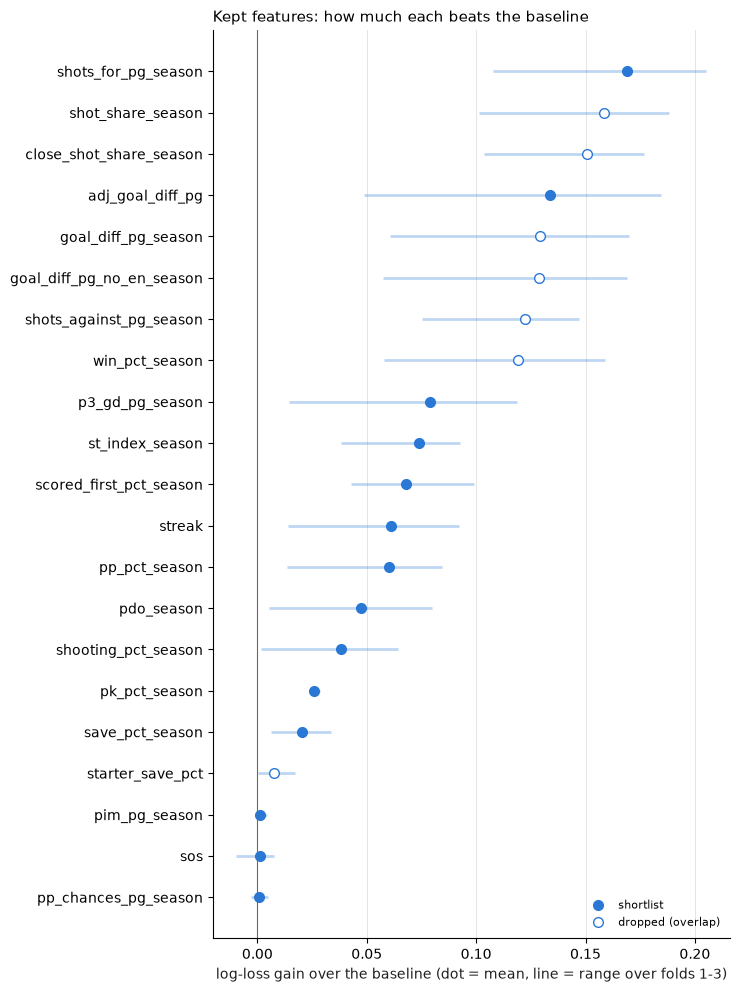

In [8]:
BLUE, MUTED, GRID, INK = "#2a78d6", "#6b6a66", "#e1e0d9", "#1f1f1d"
show = res.loc[[*shortlist, *dropped]].sort_values("mean gain")
lo = [per_fold[f]["gain"].min() for f in show.index]
hi = [per_fold[f]["gain"].max() for f in show.index]
fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(show) + 1.2))
yy = np.arange(len(show))
ax.hlines(yy, lo, hi, color=BLUE, lw=2, alpha=0.3)
on_list = [f in shortlist for f in show.index]
ax.plot(show["mean gain"].astype(float)[on_list], yy[on_list], "o", color=BLUE, ms=7, label="shortlist")
ax.plot(show["mean gain"].astype(float)[[not x for x in on_list]], yy[[not x for x in on_list]], "o",
        mfc="white", mec=BLUE, ms=7, label="dropped (overlap)")
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_yticks(yy, [f.removeprefix("diff_") for f in show.index])
ax.set_xlabel("log-loss gain over the baseline (dot = mean, line = range over folds 1-3)", color=INK)
ax.set_title("Kept features: how much each beats the baseline", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="x", color=GRID, lw=0.6)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## Confirm once on fold 4

Train on every game before fold 4, test on fold 4 (the last 115 games, including the
conference and NCAA tournaments). This is the only time fold 4 is looked at. Nothing is
re-chosen after this.


In [9]:
confirm = pd.DataFrame({
    f: score(f, [CONFIRM]).iloc[0] for f in shortlist
}).T
confirm["confirmed"] = confirm["gain"] > 0
confirm.index = [f.removeprefix("diff_") for f in confirm.index]
confirm.style.format({"gain": "{:+.4f}", "auc": "{:.3f}"})

,gain,auc,confirmed
shots_for_pg_season,+0.1275,0.761,True
adj_goal_diff_pg,+0.1355,0.771,True
p3_gd_pg_season,+0.0677,0.696,True
st_index_season,+0.0787,0.677,True
scored_first_pct_season,+0.0504,0.655,True
streak,-0.0101,0.584,False
pp_pct_season,+0.0385,0.630,True
pdo_season,+0.0706,0.679,True
shooting_pct_season,+0.0406,0.639,True
pk_pct_season,+0.0489,0.724,True


## Implications for the model

**1. Women's games are far more predictable than men's.** Shots for per game alone cuts the
baseline's log loss by about a quarter (gain 0.169 on a baseline of about 0.69; AUC 0.82). The
men's best single feature: gain 0.071, AUC 0.71. Women's D-I has wider gaps between teams.

**2. The season to date beats recent form, for every tier 1 stat**, in the order season > ewm
> last 10 > last 5 > last 3, as for the men's. That includes the special teams index, which
step 4 suggested might change during the season: its season window still predicts best.

**3. Shots dominate, and the shot stats are near copies of each other** (r = 0.95–0.96).
Shots for per game edges raw and close-game shot share and takes their place by the overlap
rule. Goal differential and win % overlap it too (r ≈ 0.9) and are dropped, but the
**schedule-adjusted goal differential** overlaps less and stays.

**4. Questions answered:**

| Question | Answer |
|---|---|
| Close-game vs raw shot share | Tied (−1.6 SE). Removing score effects didn't help prediction |
| Schedule-adjusted vs raw goal diff | Tied (+0.4 SE), but the adjusted one overlaps shots less, so it's the one on the list |
| Goal diff vs win % | **Goal diff better** (+2.6 SE) |
| Special teams index vs PP% / PK% | **Index better** (+2.5 and +2.7 SE) |
| Likely starter's save % vs team save % | **Starter worse** (−3.5 SE), as for the men's |
| Shooting % or PDO vs save % | Slightly better, not decisively (+1.6, +1.9 SE). Finishing matters in the women's game |
| 3rd-period vs full goal diff | **Full goal diff far better** (−23 SE) |

**5. Dropped by the keep rule:** times shorthanded and form vs. season (1 of 3 folds).

**6. The shortlist for step 7** (strongest first): shots for per game, schedule-adjusted goal
diff, 3rd-period goal diff, special teams index, % scoring first, streak, PP%, PDO, shooting
%, PK%, save %, PIM, strength of schedule, PP chances.

**7. Fold 4 confirms 12 of 14.** Streak and strength of schedule are **flagged** (they lose to
the baseline on the tournament games). The top features hold up: shots for per game gains
0.128 there (AUC 0.76), schedule-adjusted goal diff 0.136.
